# Indonesia vs. ASEAN: Greenhouse Gas Emissions Analysis (2015-2025)

**Author**: Narda Parama Agung Noviantoro

**Tableau Dashboard**: [ASEAN Country Emissions Analysis Dashboard](https://public.tableau.com/app/profile/narda.noviantoro/viz/ASEANCountryEmissionsAnalysisDashboard/Visualization)

**Google Slides**: [Presentation on ASEAN Country Emissions Analysis](https://docs.google.com/presentation/d/1Nx7RRnWja2BviSipnSvHHqrGtoLT-qNVVk4iKNmUa8w/edit?usp=sharing)

## **Overview**

Indonesia is one of the largest greenhouse gas emitters in ASEAN, yet it is unclear which subsectors drive its emissions. This project compares Indonesia's greenhouse gas emissions (in metric tons of CO2e) with 9 other ASEAN countries from 2015 to 2025 and identifies the subsectors that contribute the most, so reduction efforts can be prioritized where they matter.

The data comes from Climate TRACE, a global nonprofit coalition that tracks, measures, and visualizes worldwide greenhouse gas emissions and traces them to their source. It was accessed through BigQuery.

**Workflow**: BigQuery (download) → PostgreSQL (import and extract) → Python (cleaning and analysis) → Tableau (dashboard)

**Notebook structure**:
1. **Business Problem**: context, objective, and the six questions this analysis answers.
2. **Data Loading**: data source, metric choices, and the SQL queries used for extraction.
3. **Data Cleaning**: preparing the data for analysis.
4. **Analysis**: answering the six questions with visualizations, descriptive statistics, and inferential statistics.
5. **Conclusion**: key findings, recommendations, and limitations.


## **Business Problem**

**Context**: Indonesia has committed to reaching net zero emissions by 2060. However, it is also one of the largest greenhouse gas emitters in ASEAN. To get closer to this target, policymakers, researchers, and ESG professionals need to know which subsectors generate the most emissions and how emissions have moved over time.

**Objective**: Identify the subsectors that generate the most greenhouse gas emissions in Indonesia (in metric tons of CO2e) and compare Indonesia's emission trends with 9 other ASEAN countries between 2015 and 2025 using Climate TRACE data. The goal is to show where emission reduction efforts should be prioritized.

**Key Questions**:
1. What are the top 5 subsectors that generate the most emissions in Indonesia in 2025? *(Visualization)*
2. Which ASEAN country produced the highest average emissions from 2015 to 2025, and how does Indonesia compare to the other ASEAN countries? *(Visualization)*
3. When did Indonesia's emission level reach its highest point, and what is the trend from 2015 until 2025? *(Visualization)*
4. In which of the top 5 subsectors in Indonesia have emission levels consistently increased from 2015 to 2025? *(Visualization)*
5. Is Indonesia's average annual emission level (2015-2025) an outlier among ASEAN countries? *(Descriptive Statistics)*
6. How different are Indonesia's subsector emission levels between 2015 and 2025, and is this significant? *(Inferential Statistics)*

## **Data Loading**

**Data Source**: Climate TRACE's 'Country Emissions' accessed through BigQuery.

**BigQuery Source Link**: [Climate TRACE's Country Emissions Dataset](https://console.cloud.google.com/bigquery?ws=!1m5!1m4!4m3!1strace-data-383422!2sclimate_trace!3scountry_emissions)

**Climate TRACE Official Website**: [climatetrace.org/data](https://climatetrace.org/data)

**Metric Choices and Reasoning:**

The original data consisted of 9 columns and over 1 million rows. Out of everything, only 5 were chosen as relevant to this project:
1. 'iso3_country': country code, which will be used to compare Indonesia with other ASEAN countries.
2. 'subsector': emission source, which will be used to identify which subsectors generate high emission levels.
3. 'start_time': beginning of the annual period, to see emission levels trend over the years.
4. 'gas': gas types, which will be filtered to just 'co2e_100yr' as it represents all greenhouse gases (e.g. CO2, CH4, etc.) converted to CO2 equivalent for a 100-year period. This allows fair comparisons and analysis for emission levels.
5. 'emissions_quantity': the total emission levels in metric tons of CO2e. This will be the main metric of analysis.

Other columns were not considered due to lack of relevance or missing data. For instance, 'sector' had no values at all in the entire dataset. 'end_time' provides redundant information, as 'start_time' already indicates one full year for every row. 'emissions_quantity_units' and 'temporal_granularity' do not provide any analytical relevance as they only show one value throughout the dataset ('tonnes' and 'annual'). 'emissions_quantity_units' was simply used to understand that 'emissions_quantity' is in metric tons.

**Countries and Period choice:**
- The data will only focus on ASEAN countries to match the problem statement.
    - This will include BRN, IDN, KHM, LAO, MMR, MYS, PHL, SGP, THA, and VNM.
- The project will also only focus on data from 2015 to 2025. 2026 was not chosen because the data has not reached a full year yet, thus it has less data than other years and may cause unreliable emission trends during the analysis.

### Queries Used to Extract the Dataset

1. **BigQuery**: Downloads the original Climate TRACE country emissions data to a CSV file.
```sql
SELECT * FROM `trace-data-383422.climate_trace.country_emissions`;
```

2. **PostgreSQL**: Imports original CSV data into the 'country_emissions_raw' table. Metrics and rows needed are then extracted.

The below query is used to create an empty table in accordance with the nine columns available in the dataset CSV obtained from BigQuery.
```sql
CREATE TABLE country_emissions_raw (
	iso3_country VARCHAR(3),
	sector VARCHAR(100),
	subsector VARCHAR(100),
	start_time TIMESTAMP,
	end_time TIMESTAMP,
	gas VARCHAR(20),
	emissions_quantity FLOAT,
	emissions_quantity_units VARCHAR(20),
	temporal_granularity VARCHAR(20)
);
```

Importing CSV data into the table.
```sql
COPY country_emissions_raw
FROM '/tmp/country_emissions.csv'
DELIMITER ',' CSV HEADER;
```

The below query is used to display the country_emissions_raw table.
```sql
SELECT * FROM country_emissions_raw;
```

Used to count the total rows in country_emissions_raw and to check the time period of the dataset (which is 2015-2026).
```sql
SELECT COUNT(*) FROM country_emissions_raw;
SELECT MIN(start_time), MAX(start_time) FROM country_emissions_raw;
```

Extracts the 5 metrics filtered to get data of 10 ASEAN countries, co2e_100yr gas, and from 2015 to 2025.
```sql
SELECT iso3_country, subsector, start_time, gas, emissions_quantity
FROM country_emissions_raw
WHERE gas = 'co2e_100yr'
	AND iso3_country IN ('IDN', 'MYS', 'THA', 'VNM', 'PHL', 'SGP', 'MMR', 'KHM', 'LAO', 'BRN')
	AND start_time < '2026-01-01';
```

**NOTE**: 
- The extracted and filtered dataset (saved as raw_country_emissions.csv) was downloaded using the download icon on the Data Output panel in pgAdmin 4.
    - The extracted dataset has a total of 7,480 rows.

### Importing Libraries and Loading the Raw Dataset

Importing all needed libraries for the project.

In [1]:
import pandas as pd     # for data cleaning
import numpy as np  # for numerical calculations
from scipy import stats     # for statistical analysis
import matplotlib.pyplot as plt     # for data visualization
import seaborn as sns   # for more data visualization

The below code is used to load the raw data.

In [2]:
df = pd.read_csv('raw_country_emissions.csv')   # reads the csv file extracted from SQL
df.head(20) # shows the first 20 rows of the dataset

,iso3_country,subsector,start_time,gas,emissions_quantity
0,MYS,aluminum,2015-01-01 00:00:00,co2e_100yr,1.257344e+05
1,IDN,aluminum,2015-01-01 00:00:00,co2e_100yr,9.453586e+05
2,BRN,aluminum,2015-01-01 00:00:00,co2e_100yr,0.000000e+00
3,MYS,aluminum,2016-01-01 00:00:00,co2e_100yr,7.721167e+05
4,BRN,aluminum,2016-01-01 00:00:00,co2e_100yr,0.000000e+00
5,LAO,aluminum,2017-01-01 00:00:00,co2e_100yr,0.000000e+00
6,LAO,aluminum,2018-01-01 00:00:00,co2e_100yr,0.000000e+00
7,BRN,aluminum,2018-01-01 00:00:00,co2e_100yr,0.000000e+00
8,IDN,aluminum,2020-01-01 00:00:00,co2e_100yr,5.585950e+06
9,SGP,aluminum,2020-01-01 00:00:00,co2e_100yr,0.000000e+00


The below code is used to show the structure of the dataset.

In [3]:
df.shape    # shows number of rows and columns

(7480, 5)

The below code is used to show further information about the columns.

In [4]:
df.info()   # shows the data types and missing values of each column

<class 'pandas.DataFrame'>
RangeIndex: 7480 entries, 0 to 7479
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   iso3_country        7480 non-null   str    
 1   subsector           7480 non-null   str    
 2   start_time          7480 non-null   str    
 3   gas                 7480 non-null   str    
 4   emissions_quantity  7480 non-null   float64
dtypes: float64(1), str(4)
memory usage: 292.3 KB


Calculating statistical summary for the 'emissions_quantity' column.

In [5]:
print('Total data:', df['emissions_quantity'].count())    # counts total data that are not missing
print('Mean:', df['emissions_quantity'].mean())   # shows the average value
print('Median:', df['emissions_quantity'].median()) # shows the median value
print('Standard deviation:', df['emissions_quantity'].std())    # shows the standard deviation
print('Minimum:', df['emissions_quantity'].min())   # shows the minimum value
print('Q1:', df['emissions_quantity'].quantile(0.25))    # shows the first quartile (25%)
print('Q3:', df['emissions_quantity'].quantile(0.75))   # shows the third quartile (75%)
print('Max:', df['emissions_quantity'].max())   # shows the maximum value

Total data: 7480
Mean: 4642464.757650695
Median: 146387.71430750002
Standard deviation: 38489823.26036318
Minimum: -848975762.1791695
Q1: 0.0
Q3: 2691254.499289999
Max: 648958156.5365057


Identifying subsectors with negative 'emissions_quantity'.

In [6]:
df[df['emissions_quantity'] < 0]['subsector'].unique()  # shows the list of subsectors having 'emissions_quantity' below 0

<StringArray>
['net-forest-land', 'net-shrubgrass', 'net-wetland', 'removals']
Length: 4, dtype: str

Based on df.info() and the statistical summary:
- There are no missing values
- 'start_time' is still a string and must be changed to datetime
- Q1 also shows a value of 0 which indicates that at least 25% of the rows are 0
- The minimum value shows a negative value, and it has been identified that there are 4 subsectors with negative 'emissions_quantity' values, which may indicate that these sources absorbed more greenhouse gas than they released. ('net' subsectors show values where total absorption is subtracted from total emissions)

Additionally, the mean value seems to be quite far from the median, which already indicates right-skewness.

## **Data Cleaning**

Creating a copy of the raw dataset to ensure that the data cleaning process will not overwrite the original dataset. 

Then changing the datatype of 'start_time' and extracting just the year, putting it into a new column.

In [7]:
df_clean = df.copy()    # creates a copy of the raw data

df_clean['start_time'] = pd.to_datetime(df_clean['start_time']) # changes 'start_time' from string to datetime
df_clean['year'] = df_clean['start_time'].dt.year    # extracts just the year of 'start_time'
df_clean.info() # used to check if the datatype has successfully changed or not

<class 'pandas.DataFrame'>
RangeIndex: 7480 entries, 0 to 7479
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   iso3_country        7480 non-null   str           
 1   subsector           7480 non-null   str           
 2   start_time          7480 non-null   datetime64[us]
 3   gas                 7480 non-null   str           
 4   emissions_quantity  7480 non-null   float64       
 5   year                7480 non-null   int32         
dtypes: datetime64[us](1), float64(1), int32(1), str(3)
memory usage: 321.5 KB


'start_time' has successfully been converted to datetime.

The below code will help check for duplicate data and drop them if there are any.

In [8]:
print('Total duplicated rows:', df_clean.duplicated().sum())    # counts the total rows that are duplicates

df_clean = df_clean.drop_duplicates()   # deletes duplicate rows if there are any
print('Shape:', df_clean.shape) # shows the shape of the dataset after dropping duplicates if there are any

Total duplicated rows: 0
Shape: (7480, 6)


There are no duplicates in the dataset, thus no rows were dropped.

The below code will conduct a consistency check on the filtered columns: 'gas', 'iso3_country', 'year'.

This is done so that these columns only include those that are needed for the analysis.

In [9]:
print('Gas Types:', df_clean['gas'].unique())   # checks if there is only one gas type ('co2e_100yr')

print() # adds an empty line

print('Countries:', df_clean['iso3_country'].unique())  # checks if there are only ASEAN countries

print() # adds an empty line

print('Years:', np.sort(df_clean['year'].unique()))  # checks if the dataset follows a period of 2015-2025

Gas Types: <StringArray>
['co2e_100yr']
Length: 1, dtype: str

Countries: <StringArray>
['MYS', 'IDN', 'BRN', 'LAO', 'SGP', 'KHM', 'PHL', 'MMR', 'VNM', 'THA']
Length: 10, dtype: str

Years: [2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]


The dataset is already consistent with what is needed for the analysis, where 'gas' only consists of 'co2e_100yr', the dataset only includes ASEAN countries, and follows a period from 2015 to 2025.

Dropping the 4 subsectors that have negative emission levels (emissions absorption), ensuring the dataset only consists of subsectors that produce emissions (gross emissions).

In [10]:
subsectors_removed = ['net-forest-land', 'net-shrubgrass', 'net-wetland', 'removals']   # creates a list of the subsectors with negative emission levels

df_clean = df_clean[df_clean['subsector'].isin(subsectors_removed)==False]  # removes rows with the 4 subsectors

print('Total negative values:', (df_clean['emissions_quantity'] < 0).sum()) # checks if there are any negative values left in 'emissions_quantity'
print('Shape:', df_clean.shape) # shows the shape of the dataset after removing the 4 subsectors

Total negative values: 0
Shape: (7040, 6)


A total of 440 rows have been removed, as indicated by the reduced number of rows (from 7480 to 7040). There is no more data that suggests emissions absorption.

However, a limitation of this is that total emissions do not consider carbon absorption from forests and land. That said, the removal of these subsectors is necessary, because keeping them can distort the totals. For instance, emission absorption cancels out some part of real emissions, which can make a country show lower emissions when it actually is a large emitter.

The below code is used for a skewness check.

In [11]:
print('Skewness:', df_clean['emissions_quantity'].skew()) # checks for skewness

Skewness: 6.891296441012982


Based on the skewness check, the value (6.89) is far above 1, indicating that the dataset is heavily right-skewed. This means a small portion of subsectors produces a large part of emissions. The data is kept as is, because this reflects the real condition.

Knowing this, the analysis will mostly use the median and % contribution of subsectors towards emission levels. This is because the mean value is heavily inflated by very large values and may cause misleading results.

NOTE: % contribution will be calculated during the analysis.

The below code is used to delete 'start_time' as the analysis will use 'year' instead.

In [12]:
df_clean = df_clean.drop(columns=['start_time'])    # deletes 'start_time' column
df_clean.head(20)   # shows the first 20 rows of the dataset after dropping 'start_time'

,iso3_country,subsector,gas,emissions_quantity,year
0,MYS,aluminum,co2e_100yr,1.257344e+05,2015
1,IDN,aluminum,co2e_100yr,9.453586e+05,2015
2,BRN,aluminum,co2e_100yr,0.000000e+00,2015
3,MYS,aluminum,co2e_100yr,7.721167e+05,2016
4,BRN,aluminum,co2e_100yr,0.000000e+00,2016
5,LAO,aluminum,co2e_100yr,0.000000e+00,2017
6,LAO,aluminum,co2e_100yr,0.000000e+00,2018
7,BRN,aluminum,co2e_100yr,0.000000e+00,2018
8,IDN,aluminum,co2e_100yr,5.585950e+06,2020
9,SGP,aluminum,co2e_100yr,0.000000e+00,2020


Final check and saving the cleaned dataset to a csv file.

In [13]:
df_clean.info() # used to check the total rows, columns, and data types after cleaning

<class 'pandas.DataFrame'>
Index: 7040 entries, 0 to 7479
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   iso3_country        7040 non-null   str    
 1   subsector           7040 non-null   str    
 2   gas                 7040 non-null   str    
 3   emissions_quantity  7040 non-null   float64
 4   year                7040 non-null   int32  
dtypes: float64(1), int32(1), str(3)
memory usage: 302.5 KB


Based on df_clean.info(), everything is consistent and the dataset is ready for analysis.

In [14]:
df_clean.to_csv('clean_country_emissions.csv', index=False) # saves cleaned data into a csv file

## **Analysis**

#### 1. What are the top 5 subsectors that generate the most emissions in Indonesia in 2025?

Extracting data for Indonesia in 2025, then calculating the top 5 subsectors with the largest emission levels along with the % contribution towards total emissions.

In [15]:
df_IDN_2025 = df_clean[(df_clean['iso3_country'] == 'IDN') & (df_clean['year'] == 2025)]    # extracts data for Indonesia in 2025
sum_IDN_2025 = df_IDN_2025['emissions_quantity'].sum()   # calculates Indonesia's total emissions in 2025

top5_subsec_IDN = df_IDN_2025.sort_values('emissions_quantity', ascending=False).head(5)    # sorts emission levels from the largest and takes the top 5
top5_subsec_IDN['percentage'] = top5_subsec_IDN['emissions_quantity'] / sum_IDN_2025 * 100  # calculates the % contribution for each subsector

print(f"Indonesia Total Emissions 2025: {sum_IDN_2025:.2f}")  # displays total emissions
print(f"Indonesia Total % Contributions of the Top 5 Subsectors: {top5_subsec_IDN['percentage'].sum():.2f}%") # displays the total % contributions of the top 5 subsectors in Indonesia
top5_subsec_IDN[['subsector', 'emissions_quantity', 'percentage']]  # displays the top 5 subsectors with the largest emissions

Indonesia Total Emissions 2025: 1841972975.38
Indonesia Total % Contributions of the Top 5 Subsectors: 60.20%


,subsector,emissions_quantity,percentage
394,electricity-generation,2.879844e+08,15.634561
5879,other-agricultural-soil-emissions,2.565914e+08,13.930250
2861,other-solid-fuels,2.206445e+08,11.978703
1396,forest-land-clearing,1.799160e+08,9.767570
2505,road-transportation,1.637481e+08,8.889822


Creates a bar chart of the top 5 subsectors with the largest emission levels in Indonesia in 2025.

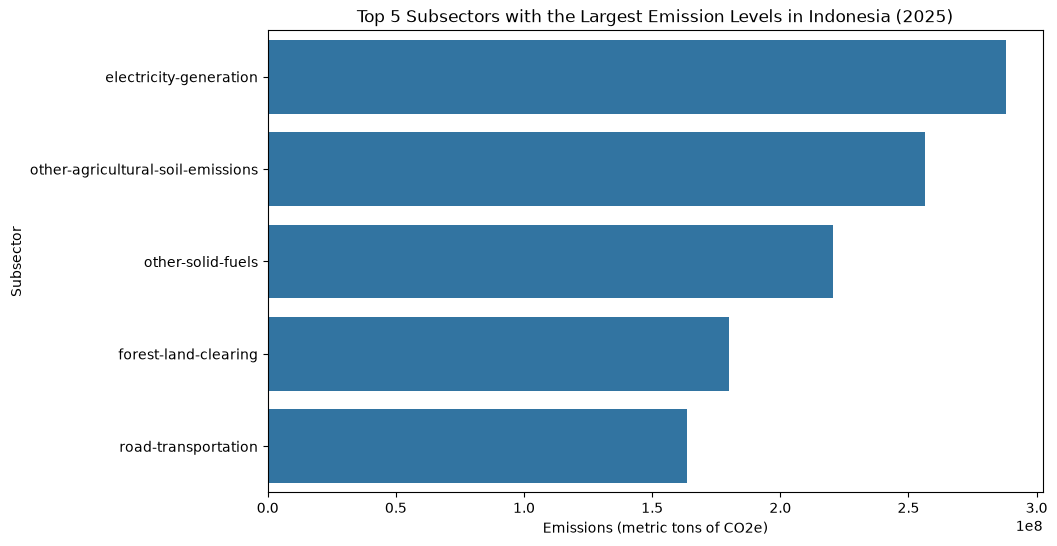

In [16]:
plt.figure(figsize=(10,6))  # sets the size of the chart
sns.barplot(data=top5_subsec_IDN, x='emissions_quantity', y='subsector')    # creates the bar chart
plt.title('Top 5 Subsectors with the Largest Emission Levels in Indonesia (2025)')  # creates the chart title
plt.xlabel('Emissions (metric tons of CO2e)')  # creates label for the x axis
plt.ylabel('Subsector') # creates label for the y axis
plt.show()  # displays the chart

**Insights:**

The largest emitter in Indonesia in 2025 is 'electricity-generation' at 15.63%, followed by 'other-agricultural-soil-emissions' with 13.93%. 'other-solid-fuels' holds 11.98% of total emissions, while 'forest-land-clearing' holds 9.77% and 'road-transportation' 8.89%.

These five subsectors contribute to a total of 60.2% of the total emissions in Indonesia, thus emission reduction efforts should be prioritized towards the energy, agriculture, forestry, and road transportation sectors.

That said, this analysis only covers the year 2025, and has not shown whether emissions in these subsectors have increased or decreased over the years prior, which will be discussed in Analysis 4.

#### 2. Which ASEAN country produced the highest average emissions from 2015 to 2025, and how does Indonesia compare to the other ASEAN countries?

Calculating the total emissions of each ASEAN country every year, then calculating the average yearly emissions level from 2015 to 2025.

In [17]:
yearly_emissions = df_clean.groupby(['iso3_country', 'year'])['emissions_quantity'].sum().reset_index() # calculates total emissions of each country per year

average_emissions = yearly_emissions.groupby('iso3_country')['emissions_quantity'].mean().sort_values(ascending=False).reset_index()    # calculates average emission levels for the whole 2015-2025 for each country, sorting from the largest
average_emissions['percentage'] = average_emissions['emissions_quantity'] / average_emissions['emissions_quantity'].sum() * 100 # calculates the % contribution of each country towards the total emissions of ASEAN

average_emissions # displays average emissions of each country for the whole 2015-2025

,iso3_country,emissions_quantity,percentage
0,IDN,1.653948e+09,39.336656
1,THA,5.398499e+08,12.839517
2,VNM,4.924509e+08,11.712203
3,MYS,4.159024e+08,9.891614
4,MMR,3.685436e+08,8.765254
5,PHL,2.565035e+08,6.100549
6,LAO,1.949453e+08,4.636481
7,KHM,1.590301e+08,3.782292
8,SGP,1.109879e+08,2.639681
9,BRN,1.243520e+07,0.295752


Creates a bar chart of average emissions per year for each ASEAN country.

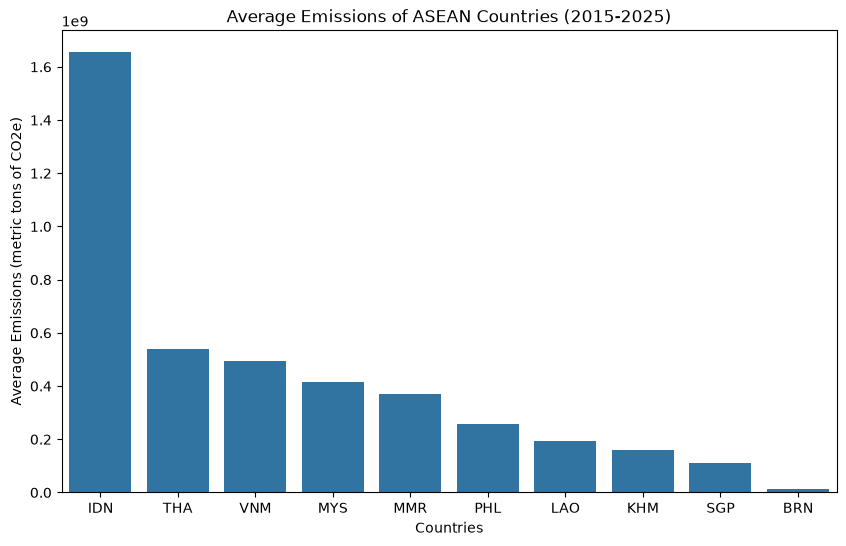

In [18]:
plt.figure(figsize=(10,6))  # sets the size of the chart
sns.barplot(data=average_emissions, x='iso3_country', y='emissions_quantity')   # creates the bar chart
plt.title('Average Emissions of ASEAN Countries (2015-2025)')    # creates the bar chart title
plt.xlabel('Countries') # creates label for the x axis
plt.ylabel('Average Emissions (metric tons of CO2e)')   # creates label for the y axis
plt.show()  # displays the chart

**Insights:**

Based on the calculations and chart, Indonesia holds the largest average emission levels for the period of 2015-2025, around 1.65 billion metric tons CO2e and holds about 39.34% of total emissions in ASEAN. This is about three times larger than Thailand, which holds only about 12.84% of total emissions. Brunei, on the other hand, holds the lowest average emission levels with only 0.30% of total emissions.

However, because this analysis uses total emissions, population and land size of each country become factors in influencing emission levels, which explains why Indonesia is the largest emitter and Singapore and Brunei are among the smallest emitters.

#### 3. When did Indonesia's emission level reach its highest point, and what is the trend from 2015 until 2025?

Extracts yearly total emissions for Indonesia only and sorts from the largest emission.

In [19]:
yearly_emissions_IDN = yearly_emissions[yearly_emissions['iso3_country'] == 'IDN']  # extracts the yearly total emissions for Indonesia

yearly_emissions_IDN.sort_values('emissions_quantity', ascending=False)  # sorts from the largest emission level

,iso3_country,year,emissions_quantity
19,IDN,2023,1.879936e+09
21,IDN,2025,1.841973e+09
20,IDN,2024,1.805599e+09
11,IDN,2015,1.773080e+09
15,IDN,2019,1.735503e+09
18,IDN,2022,1.651695e+09
14,IDN,2018,1.586152e+09
17,IDN,2021,1.517901e+09
16,IDN,2020,1.497866e+09
12,IDN,2016,1.487584e+09


Creates a line chart to visualize Indonesia's yearly emission trend.

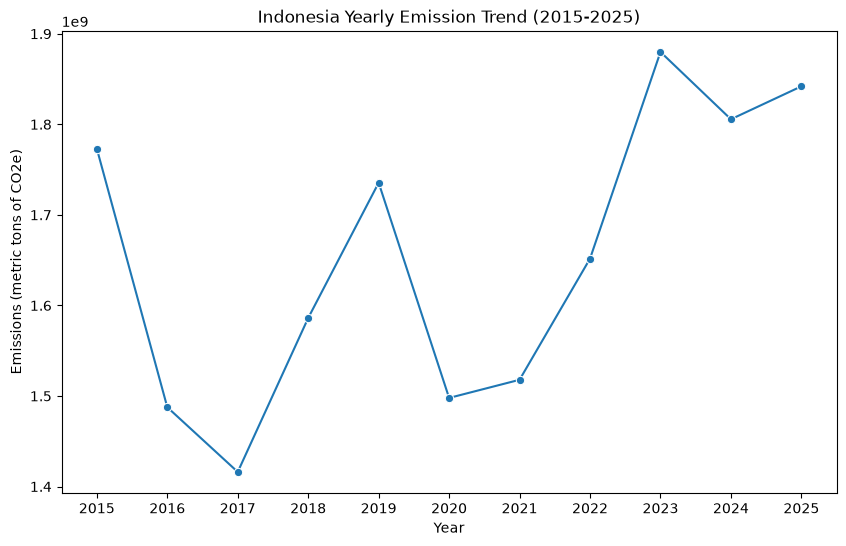

In [20]:
plt.figure(figsize=(10,6))  # sets the chart size
sns.lineplot(data=yearly_emissions_IDN, x='year', y='emissions_quantity', marker='o')  # creates the line chart
plt.xticks(yearly_emissions_IDN['year'])    # shows the years on the x axis
plt.title('Indonesia Yearly Emission Trend (2015-2025)')    # creates the title for the line chart
plt.xlabel('Year')  # creates label for the x axis
plt.ylabel('Emissions (metric tons of CO2e)')   # creates label for the y axis
plt.show()  # shows the line chart

**Insights:**

Indonesia's emission levels reached their highest in 2023 at around 1.88 billion metric tons CO2e, while its lowest emission happened in 2017 at around 1.42 billion metric tons CO2e. The trend is quite fluctuating, where there is a big reduction in 2016 to 2017 and 2020. The 2020 drop is possibly due to the COVID-19 pandemic as activity lessens. There is a consistent increase from 2021 until 2023, possibly due to the resumption of activities post-COVID. 

Overall, 2025's emission levels are not far off 2015's emissions. In fact, it is slightly higher. This indicates that there haven't been improvements towards reaching the 2060 net-zero target.

It should also be noted that this part of the analysis has not shown which subsectors push these increases and decreases in emissions. This will be discussed in Analysis 4.

#### 4. In which of the top 5 subsectors in Indonesia have emission levels consistently increased from 2015 to 2025?

Extracting the top 5 subsectors in Indonesia with the highest emission levels, then comparing emission levels in 2015 and 2025.

In [21]:
top5_idn2 = top5_subsec_IDN['subsector']    # extracts the names of the 5 highest emitting subsectors

df_trend_idn = df_clean[(df_clean['iso3_country'] == 'IDN') & (df_clean['subsector'].isin(top5_idn2))]  # extracts Indonesia's top 5 highest emitting subsectors for each year

df_trend_idn[df_trend_idn['year'].isin([2015, 2025])].sort_values(['subsector', 'year'])    # displays emission levels in 2015 and 2025 for each subsector (for comparison)

,iso3_country,subsector,gas,emissions_quantity,year
752,IDN,electricity-generation,co2e_100yr,1.910066e+08,2015
394,IDN,electricity-generation,co2e_100yr,2.879844e+08,2025
4245,IDN,forest-land-clearing,co2e_100yr,2.486217e+08,2015
1396,IDN,forest-land-clearing,co2e_100yr,1.799160e+08,2025
2131,IDN,other-agricultural-soil-emissions,co2e_100yr,2.479461e+08,2015
5879,IDN,other-agricultural-soil-emissions,co2e_100yr,2.565914e+08,2025
3115,IDN,other-solid-fuels,co2e_100yr,8.698163e+07,2015
2861,IDN,other-solid-fuels,co2e_100yr,2.206445e+08,2025
3538,IDN,road-transportation,co2e_100yr,1.288293e+08,2015
2505,IDN,road-transportation,co2e_100yr,1.637481e+08,2025


Creates a line chart to show the trend of Indonesia's top 5 highest emitting subsectors from 2015 to 2025.

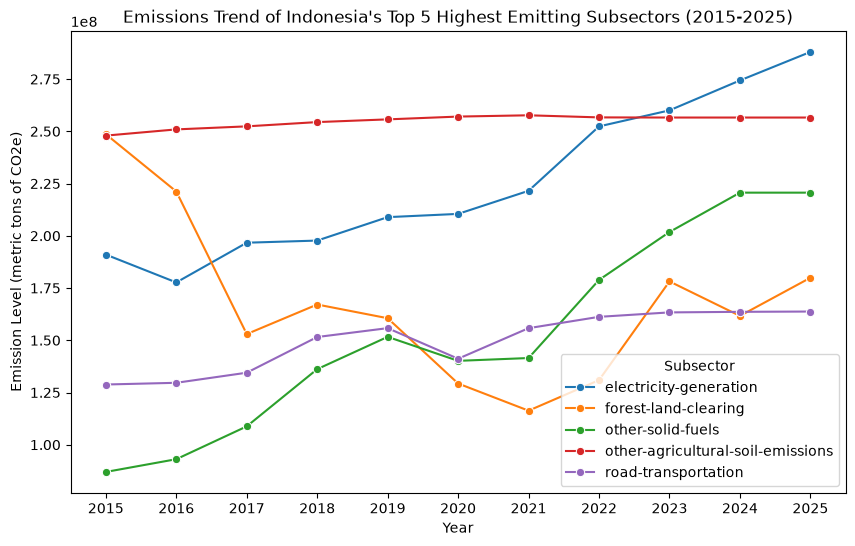

In [22]:
plt.figure(figsize=(10,6))  # sets chart size
sns.lineplot(data=df_trend_idn, x='year', y='emissions_quantity', hue='subsector', marker='o')   # creates the line chart
plt.xticks(df_trend_idn['year'].unique())   # displays each year on the x axis
plt.title("Emissions Trend of Indonesia's Top 5 Highest Emitting Subsectors (2015-2025)")   # creates the title
plt.xlabel('Year')  # creates label for x axis
plt.ylabel('Emission Level (metric tons of CO2e)')  # creates label for y axis
plt.legend(title='Subsector') # creates legend for each subsector
plt.show()  # displays the line chart

**Insights:**

Based on the above calculations and chart, 'electricity-generation' and 'other-solid-fuels' show the clearest uptrend. 'electricity-generation' increased from around 191 million metric tons CO2e in 2015 to 288 million metric tons CO2e in 2025, having only dropped slightly in 2016. 'other-solid-fuels' showed the biggest increase with 87 million metric tons CO2e in 2015 to around 221 million metric tons CO2e in 2025, with a drop in 2020. This is followed by 'road-transportation' where emission levels increased from around 129 million to 164 million metric tons CO2e, though its increase has plateaued since 2022. 'other-agricultural-soil-emissions', on the other hand, remains stable throughout 2015-2025, while 'forest-land-clearing' decreased drastically from around 249 million in 2015 to 180 million metric tons CO2e in 2025, though the line chart suggests a fluctuating trend.

Overall, this suggests that Indonesia's high emission levels are primarily influenced by the energy sector.

#### 5. Is Indonesia's average annual emission level (2015-2025) an outlier among ASEAN countries?

Calculating the mean and median of the average yearly emission levels of ASEAN countries, then calculating the outliers using Tukey's rule.

In [23]:
print('Mean:', average_emissions['emissions_quantity'].mean())   # calculates the mean value
print('Median:', average_emissions['emissions_quantity'].median())  # calculates the median value

q1 = average_emissions['emissions_quantity'].quantile(0.25) # calculates the first quartile
q3 = average_emissions['emissions_quantity'].quantile(0.75) # calculates the third quartile
iqr = q3 - q1   # calculates the interquartile range

upper = q3 + 1.5*iqr    # calculates the upper boundary of the outlier
lower = q1 - 1.5*iqr    # calculates the lower boundary of the outlier

print('Upper Boundary:', upper) # displays upper boundary
print('Lower Boundary:', lower)  # displays lower boundary

Mean: 420459650.8145788
Median: 312523514.8000557
Upper Boundary: 931271056.0575997
Lower Boundary: -289948350.5231177


Displaying countries where average emission levels are outside the outlier boundaries.

In [24]:
country_emissions_outliers = average_emissions[(average_emissions['emissions_quantity'] < lower) | (average_emissions['emissions_quantity'] > upper)]   # extracts countries where emission levels are outside the outlier boundaries

country_emissions_outliers  # displays outliers

,iso3_country,emissions_quantity,percentage
0,IDN,1.653948e+09,39.336656


**Insights:**

According to the above calculations, Indonesia's average yearly emission level is indeed an outlier among ASEAN countries, and it is the only outlier, showing a staggering average of 1.65 billion metric tons CO2e, well above the upper boundary of 931 million metric tons CO2e. This can also be seen in the mean value (around 420 million metric tons CO2e) where it is higher than the median (around 313 million metric tons CO2e), indicating that the average emission levels in ASEAN are being pulled up by Indonesia's large average emission levels. 

It should be noted that the outlier boundaries are only based on a small sample (10 data points), making the analysis easily skewed by a unique value. Additionally, the lower boundary is negative, making it impossible to detect lower outliers. However, this is not an issue here, since the goal is only to check whether Indonesia is an outlier.

#### 6. How different are Indonesia's subsector emission levels between 2015 and 2025, and is this significant?

Hypotheses for the t-test using a 0.05 significance level:
- H0: There is no difference in average emissions in Indonesia's subsectors between 2015 and 2025.
- H1: There is a difference in average emissions in Indonesia's subsectors between 2015 and 2025.

Extracting emission levels for each subsector in Indonesia in 2015 and 2025, then sorting based on subsector.

In [25]:
df_IDN = df_clean[df_clean['iso3_country'] == 'IDN']    # extracts data for Indonesia
IDN_data_2015 = df_IDN[df_IDN['year'] == 2015].sort_values('subsector') # extracts 2015 data and sorts by subsector
IDN_data_2025 = df_IDN[df_IDN['year'] == 2025].sort_values('subsector') # extracts 2025 data and sorts by subsector

print('Total Subsectors in 2015:', len(IDN_data_2015))  # counts the number of subsectors in 2015
print('Total Subsectors in 2025:', len(IDN_data_2025))  # checks that the number of subsectors in 2025 is the same as in 2015

print() # creates an empty line

print('Mean (2015):', IDN_data_2015['emissions_quantity'].mean())   # calculates the average emissions of subsectors in 2015
print('Mean (2025):', IDN_data_2025['emissions_quantity'].mean())   # calculates the average emissions of subsectors in 2025

print() # creates an empty line

print('Median (2015):', IDN_data_2015['emissions_quantity'].median())    # calculates the median values of emissions of subsectors in 2015
print('Median (2025):', IDN_data_2025['emissions_quantity'].median())    # calculates the median values of emissions of subsectors in 2025


Total Subsectors in 2015: 64
Total Subsectors in 2025: 64

Mean (2015): 27704379.435189188
Mean (2025): 28780827.740284257

Median (2015): 3977639.859259722
Median (2025): 6186036.82506158


Conducting a paired t-test to test whether there is a significant difference in emissions of subsectors between 2015 and 2025.

In [26]:
t_stat, p_val = stats.ttest_rel(IDN_data_2015['emissions_quantity'], IDN_data_2025['emissions_quantity'])   # conducts paired t-test between 2015 and 2025 emissions

print('t-statistic:', t_stat)  # displays t_stat value
print('p_value:', p_val)    # displays p-value

t-statistic: -0.21812117645991344
p_value: 0.8280396877520456


**Insights:**

Based on the t-test, the p-value (0.83) is larger than the 0.05 significance level. Therefore, we fail to reject the null hypothesis. This means that there is no statistically significant difference in average emissions of Indonesian subsectors between 2015 and 2025. Although the mean values show a slight increase (around 27.7 million to 28.8 million metric tons CO2e) and the median value also increased (around 3.98 million to 6.19 million metric tons CO2e) from 2015 to 2025, the difference is not large enough to be considered significant. This is possibly due to the inconsistent rise and drop of emission levels between subsectors.

This also means that over this 11-year period, emission levels in Indonesia have not experienced notable reductions that would contribute towards the 2060 net zero target. That said, since the data is right-skewed, the results of the paired t-test may be influenced by some subsectors with very large changes in emission levels.

## **Conclusion**

Based on the overall analysis of Climate TRACE's data from 2015-2025, Indonesia is the largest greenhouse gas emitter in ASEAN with an average of around 1.65 billion metric tons CO2e per year, contributing to about 39.34% of the total emissions produced by ASEAN countries. Statistically, Indonesia is also an outlier among ASEAN countries. Indonesia's highest emitting year was in 2023, and based on the paired t-test, there was no significant difference in emission levels of subsectors between 2015 and 2025. This indicates that there were no notable reductions in emission levels over the 11-year period. 

Moreover, in 2025, the top 5 highest-emitting subsectors in Indonesia are 'electricity-generation', 'other-agricultural-soil-emissions', 'other-solid-fuels', 'forest-land-clearing', and 'road-transportation'. These contribute 60.2% of Indonesia's total emissions, with 'electricity-generation' and 'other-solid-fuels' having the clearest uptrend from 2015 to 2025.

**Key Takeaway**: Indonesia's emissions are concentrated in energy-related subsectors and have not meaningfully declined since 2015, so energy is where reduction efforts will have the most impact.

**Recommendation:**

Policymakers are suggested to prioritize emission reduction efforts towards the energy sector, particularly power plants and solid fuels. For instance, transitioning towards renewable energy may be a viable option. These focused efforts will help Indonesia move closer towards its 2060 net zero target.

Businesses and investors should prioritize ESG and decarbonization efforts on operations that are heavy on energy. Switching to renewable energy and renewable electricity are also viable options.

**Limitations:**

It should be noted that the analysis conducted uses gross emissions, thus it does not take into account carbon absorption levels in the forestry and land sectors.

Additionally, emission level comparisons between countries use total emissions, and not emissions per capita. As such, factors like population and land size play a role in influencing the results.